# Modelo de Fama-French de 3 factores
**MA2003B — Aplicación de métodos multivariados en ciencia de datos**
Prof. Dr. Jonathan Montalvo Urquizo · Octubre 2026

Estimación por mínimos cuadrados (factorización QR) de las exposiciones de cuatro activos a los factores de mercado, tamaño (SMB) y valor (HML).

| Activo | Tipo | Sector |
|---|---|---|
| MSFT | Acción | Tecnología |
| XLK | ETF | Tecnología (Technology Select Sector SPDR) |
| VOO | ETF | Mercado amplio (S&P 500) |
| JPM | Acción | Financiero |

Con autorización del profesor se usan acciones individuales y ETFs en lugar de 4 ETFs sectoriales. MSFT es uno de los principales componentes de XLK, y MSFT, JPM y las empresas de XLK forman parte del S&P 500 que replica VOO, por lo que se esperan correlaciones altas entre estos activos.

## 1.2 Descarga y preparación de datos
Rendimientos mensuales a partir de los precios de cierre ajustados de Yahoo Finance. Como VOO cotiza desde septiembre de 2010, el periodo común de los cuatro activos inicia en octubre de 2010.

In [15]:
import yfinance as yf
import pandas as pd
import numpy as np
import math
import os
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

# Cada figura se guarda interactiva y como imagen estática (visible en GitHub)
pio.renderers.default = "plotly_mimetype+png"

USE_FAMAFRENCH_3 = True
tickers = ["MSFT", "XLK", "VOO", "JPM"]
fecha_inicio = "2000-01-01"
fecha_fin = "2026-10-01"

# Tablas (.tex, .csv) y figuras (.png) para el reporte
CARPETA_RESULTADOS = "resultados"
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)


def guardar_figura(fig, nombre, ancho=1000):
    """Guarda la figura como PNG en la carpeta de resultados y la muestra."""
    fig.write_image(os.path.join(CARPETA_RESULTADOS, f"{nombre}.png"), width=ancho, scale=2)
    fig.show()

In [16]:
datos_diarios = yf.download(tickers, start=fecha_inicio, end=fecha_fin,
                            auto_adjust=True, progress=False)
precios_diarios = datos_diarios["Close"]
precios_mensuales = precios_diarios.resample("ME").last()
rendimientos = (precios_mensuales / precios_mensuales.shift(1)) - 1
rendimientos = rendimientos.dropna()
print(rendimientos.head())
print("Dimensiones rendimientos:", rendimientos.shape)


Ticker           JPM      MSFT       VOO       XLK
Date                                              
2010-10-31 -0.010022  0.089016  0.037754  0.057776
2010-11-30 -0.006112 -0.047049 -0.001108 -0.016427
2010-12-31  0.134224  0.104909  0.069210  0.055556
2011-01-31  0.060623 -0.006450  0.022234  0.031759
2011-02-28  0.038941 -0.035805  0.034664  0.021932
Dimensiones rendimientos: (192, 4)


Factores mensuales de Fama-French: lectura del archivo limpio, conversión de porcentajes a decimales y eliminación de filas vacías.

**Nota sobre el archivo:** siguiendo el template del profesor, se usa `F-F_Research_Data_5_Factors_2x3` (Data Library de Ken French), editado para dejar solo la tabla mensual y filtrado a las columnas del modelo FF3. El SMB de este archivo se construye como el promedio de tres ordenamientos (por B/M, rentabilidad e inversión), por lo que difiere ligeramente del SMB del archivo de 3 factores (`F-F_Research_Data_Factors`).

In [17]:
# Archivo descargado de la Data Library de Ken French (F-F_Research_Data_5_Factors_2x3)
# y editado para dejar solo la tabla de factores mensuales.
DATAFILE_PATH = "fama_french_factors_clean.csv"
factores = pd.read_csv(DATAFILE_PATH)

# Limpiar los nombres de columnas (sin espacios) y asignar fechas como índice
factores.columns = factores.columns.str.strip()
factores["YYYYMM"] = factores["YYYYMM"].astype(str).str.strip()
factores["Fecha"] = pd.to_datetime(factores["YYYYMM"], format="%Y%m")
factores = factores.set_index("Fecha")

# Conservar los factores disponibles
columnas_factores = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "RF"]
factores = factores[columnas_factores]

# Convertir a formato numérico y porcentajes a decimales
factores = factores.apply(pd.to_numeric, errors="coerce") / 100

# Eliminar filas incompletas
factores = factores.dropna()

if USE_FAMAFRENCH_3:
    # Conservar solamente las columnas del modelo FF3
    factores = factores[["Mkt-RF", "SMB", "HML", "RF"]]

print("Primeras filas de los factores (Fama-French):")
print(factores.head())
print("Dimensiones factores:", factores.shape)
print("Rango de fechas:", factores.index.min(), "a", factores.index.max())

Primeras filas de los factores (Fama-French):
            Mkt-RF     SMB     HML      RF
Fecha                                     
1963-07-01 -0.0039 -0.0048 -0.0084  0.0027
1963-08-01  0.0508 -0.0080  0.0172  0.0025
1963-09-01 -0.0157 -0.0043 -0.0002  0.0027
1963-10-01  0.0254 -0.0134 -0.0003  0.0029
1963-11-01 -0.0086 -0.0085  0.0178  0.0027
Dimensiones factores: (758, 4)
Rango de fechas: 1963-07-01 00:00:00 a 2026-08-01 00:00:00


Unión de ambas fuentes usando solo los meses comunes y cálculo del rendimiento en exceso $R_i - R_f$.

In [18]:
rendimientos.index = rendimientos.index.to_period("M")
factores.index = factores.index.to_period("M")

datos = rendimientos.join(factores, how="inner").dropna()

for t in tickers:
    datos[f"{t}_exceso"] = datos[t] - datos["RF"]

print("Primeras filas combinadas:")
print(datos.head())
print("Dimensiones finales:", datos.shape)
print("Periodo comun:", datos.index.min(), "a", datos.index.max())

Primeras filas combinadas:
              JPM      MSFT       VOO       XLK  Mkt-RF     SMB     HML      RF  MSFT_exceso  XLK_exceso  VOO_exceso  JPM_exceso
Date                                                                                                                            
2010-10 -0.010022  0.089016  0.037754  0.057776  0.0387  0.0073 -0.0246  0.0001     0.088916    0.057676    0.037654   -0.010122
2010-11 -0.006112 -0.047049 -0.001108 -0.016427  0.0059  0.0354 -0.0090  0.0001    -0.047149   -0.016527   -0.001208   -0.006212
2010-12  0.134224  0.104909  0.069210  0.055556  0.0682  0.0097  0.0356  0.0001     0.104809    0.055456    0.069110    0.134124
2011-01  0.060623 -0.006450  0.022234  0.031759  0.0198 -0.0231  0.0061  0.0001    -0.006550    0.031659    0.022134    0.060523
2011-02  0.038941 -0.035805  0.034664  0.021932  0.0348  0.0165  0.0118  0.0001    -0.035905    0.021832    0.034564    0.038841
Dimensiones finales: (191, 12)
Periodo comun: 2010-10 a 2026-08


## 1.3 Estimación por mínimos cuadrados (QR)
Con $X = QR$, las ecuaciones normales $(X^TX)\hat\theta = X^Ty$ se reducen a $R\hat\theta = Q^Ty$, que se resuelve por sustitución hacia atrás (sin calcular inversas). Las funciones siguientes calculan los p-values de la $t$ de Student sin usar scipy.

In [19]:
def _betacf(a, b, x, max_iter=200, eps=3e-14):
    """Fracción continua para la función beta incompleta (Lentz)."""
    qab, qap, qam = a + b, a + 1.0, a - 1.0
    c = 1.0
    d = 1.0 - qab * x / qap
    if abs(d) < 1e-30:
        d = 1e-30
    d = 1.0 / d
    h = d
    for m in range(1, max_iter + 1):
        m2 = 2 * m
        aa = m * (b - m) * x / ((qam + m2) * (a + m2))
        d = 1.0 + aa * d
        if abs(d) < 1e-30:
            d = 1e-30
        c = 1.0 + aa / c
        if abs(c) < 1e-30:
            c = 1e-30
        d = 1.0 / d
        h *= d * c
        aa = -(a + m) * (qab + m) * x / ((a + m2) * (qap + m2))
        d = 1.0 + aa * d
        if abs(d) < 1e-30:
            d = 1e-30
        c = 1.0 + aa / c
        if abs(c) < 1e-30:
            c = 1e-30
        d = 1.0 / d
        delta = d * c
        h *= delta
        if abs(delta - 1.0) < eps:
            break
    return h


def _betai(a, b, x):
    """Función beta incompleta regularizada I_x(a,b)."""
    if x <= 0.0:
        return 0.0
    if x >= 1.0:
        return 1.0
    lbeta = math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b)
    bt = math.exp(lbeta + a * math.log(x) + b * math.log(1.0 - x))
    if x < (a + 1.0) / (a + b + 2.0):
        return bt * _betacf(a, b, x) / a
    return 1.0 - bt * _betacf(b, a, 1.0 - x) / b


def t_cdf(t, df):
    """CDF de la t de Student."""
    x = df / (df + t * t)
    p = 0.5 * _betai(df / 2.0, 0.5, x)
    return 1.0 - p if t > 0 else p


def t_pvalue_dos_colas(t, df):
    """p-value bilateral."""
    return 2.0 * (1.0 - t_cdf(abs(t), df))

In [20]:
def sustitucion_atras(R, b):
    """Resuelve R x = b con R triangular superior."""
    k = R.shape[0]
    x = np.zeros_like(b, dtype=float)
    for i in range(k - 1, -1, -1):
        x[i] = (b[i] - R[i, i + 1:] @ x[i + 1:]) / R[i, i]
    return x


def sustitucion_adelante(L, b):
    """Resuelve L x = b con L triangular inferior."""
    k = L.shape[0]
    x = np.zeros_like(b, dtype=float)
    for i in range(k):
        x[i] = (b[i] - L[i, :i] @ x[:i]) / L[i, i]
    return x


def ols_qr(X, y):
    """
    Estima y = X theta + eps por MCO usando factorización QR.
    Devuelve theta, residuos, R2, SE, t-stats y p-values.
    No calcula ninguna inversa: solo sustituciones triangulares.
    """
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1, 1)
    n, k = X.shape

    if n == 0:
        raise ValueError("X tiene 0 filas: revisa que 'datos' no esté vacío.")
    if n < k:
        raise ValueError(f"X tiene {n} filas y {k} columnas: no hay suficientes observaciones.")

    Q, R = np.linalg.qr(X, mode="reduced")
    if np.any(np.abs(np.diag(R)) < 1e-10):
        raise ValueError("X no tiene rango completo: revisa los factores.")

    # X = QR  =>  (X^T X) theta = X^T y  se reduce a  R theta = Q^T y
    theta = sustitucion_atras(R, Q.T @ y)

    y_hat = X @ theta
    resid = y - y_hat

    ss_res = float((resid.T @ resid)[0, 0])
    ss_tot = float(((y - y.mean()) ** 2).sum())
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else float("nan")

    gl = n - k
    if gl <= 0:
        raise ValueError(f"Grados de libertad no positivos: n={n}, k={k}.")
    sigma2 = ss_res / gl

    # Var(theta) = sigma2 (X^T X)^{-1} = sigma2 (R^T R)^{-1}.
    # Para la diagonal se resuelve R^T z = e_j y luego R w = z; se toma w_j.
    diag_XtX_inv = np.zeros(k)
    for j in range(k):
        e_j = np.zeros((k, 1))
        e_j[j] = 1.0
        z = sustitucion_adelante(R.T, e_j)
        w = sustitucion_atras(R, z)
        diag_XtX_inv[j] = w[j, 0]

    se = np.sqrt(sigma2 * diag_XtX_inv).reshape(-1, 1)
    t_stats = theta / se
    p_values = np.array([t_pvalue_dos_colas(float(t_stats[i, 0]), gl)
                         for i in range(k)]).reshape(-1, 1)

    return {
        "theta": theta,
        "se": se,
        "t": t_stats,
        "p": p_values,
        "resid": resid,
        "y_hat": y_hat,
        "y": y,
        "R2": r2,
        "n": n,
        "k": k,
    }

## 1.4 Estimaciones
Coeficientes $\hat\alpha, \hat\beta_M, \hat s, \hat h$ con errores estándar, estadísticos $t$, p-values y $R^2$ de cada activo.

In [21]:
# --- Verificaciones de sanidad ---
print("datos.shape:", datos.shape)
assert len(datos) > 10, f"datos tiene solo {len(datos)} filas: revisa descarga y join."
for c in ["Mkt-RF", "SMB", "HML"]:
    assert datos[c].std() > 1e-6, f"El factor {c} está constante."

# --- Matriz X común (intercepto + 3 factores) ---
X = np.column_stack([
    np.ones(len(datos)),
    datos["Mkt-RF"].values.astype(float),
    datos["SMB"].values.astype(float),
    datos["HML"].values.astype(float),
])
print("X.shape:", X.shape, "| n filas datos:", len(datos))

nombres_coef = ["alpha", "beta_M", "s_SMB", "h_HML"]

# --- Ajustar los 4 ETFs ---
resultados = {}
for t in tickers:
    y = datos[f"{t}_exceso"].values.astype(float)
    resultados[t] = ols_qr(X, y)

# --- Tabla resumen ---
filas_tabla = []
for t in tickers:
    r = resultados[t]
    fila = {"Activo": t, "R2": r["R2"], "n": r["n"]}
    for j, nombre in enumerate(nombres_coef):
        fila[nombre]         = float(r["theta"][j, 0])
        fila[f"SE_{nombre}"] = float(r["se"][j, 0])
        fila[f"t_{nombre}"]  = float(r["t"][j, 0])
        fila[f"p_{nombre}"]  = float(r["p"][j, 0])
    filas_tabla.append(fila)

# Los valores se guardan sin redondear; solo se redondean al mostrarlos
# (R² con 3 decimales en todas las salidas: gráficas, tabla y LaTeX)
tabla = pd.DataFrame(filas_tabla).set_index("Activo")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
print(tabla.round(4).assign(R2=tabla["R2"].round(3)))

datos.shape: (191, 12)
X.shape: (191, 4) | n filas datos: 191
           R2    n   alpha  SE_alpha  t_alpha  p_alpha  beta_M  SE_beta_M  t_beta_M  p_beta_M   s_SMB  SE_s_SMB  t_s_SMB  p_s_SMB   h_HML  SE_h_HML  t_h_HML  p_h_HML
Activo                                                                                                                                                               
MSFT    0.496  191  0.0055    0.0035   1.5727   0.1175  1.0671     0.0851   12.5450       0.0 -0.7673    0.1405  -5.4604    0.000 -0.3191    0.1097  -2.9081   0.0041
XLK     0.839  191  0.0025    0.0016   1.5647   0.1194  1.1638     0.0393   29.6307       0.0 -0.3369    0.0649  -5.1919    0.000 -0.3277    0.0507  -6.4672   0.0000
VOO     0.996  191  0.0000    0.0002   0.1399   0.8889  0.9856     0.0050  197.5790       0.0 -0.1352    0.0082 -16.4022    0.000  0.0390    0.0064   6.0532   0.0000
JPM     0.677  191  0.0025    0.0031   0.8242   0.4109  1.1808     0.0742   15.9206       0.0  0.0756    0.1

In [22]:
print("Mayor sensibilidad al mercado:", tabla["beta_M"].idxmax(),
      f"(beta_M = {tabla['beta_M'].max():.3f})")
print()
print("Exposiciones a tamaño (SMB) y valor (HML):")
print(tabla[["s_SMB", "p_s_SMB", "h_HML", "p_h_HML"]].round(4))

Mayor sensibilidad al mercado: JPM (beta_M = 1.181)

Exposiciones a tamaño (SMB) y valor (HML):
         s_SMB  p_s_SMB   h_HML  p_h_HML
Activo                                  
MSFT   -0.7673    0.000 -0.3191   0.0041
XLK    -0.3369    0.000 -0.3277   0.0000
VOO    -0.1352    0.000  0.0390   0.0000
JPM     0.0756    0.538  0.8693   0.0000


### Matriz de correlaciones de los rendimientos excedentes

Matriz de correlaciones de rendimientos excedentes:
        MSFT     XLK     VOO     JPM
MSFT  1.0000  0.6888  0.6099  0.3758
XLK   0.6888  1.0000  0.8765  0.4752
VOO   0.6099  0.8765  1.0000  0.6973
JPM   0.3758  0.4752  0.6973  1.0000


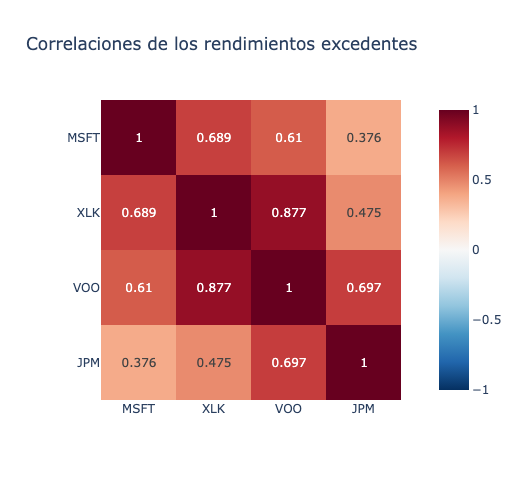

In [23]:
excesos = datos[[f"{t}_exceso" for t in tickers]].copy()
excesos.columns = tickers
matriz_corr = excesos.corr()
print("Matriz de correlaciones de rendimientos excedentes:")
print(matriz_corr.round(4))

fig = px.imshow(matriz_corr.round(3), text_auto=True, zmin=-1, zmax=1,
                color_continuous_scale="RdBu_r",
                title="Correlaciones de los rendimientos excedentes")
fig.update_layout(width=520, height=480)
guardar_figura(fig, "correlaciones", ancho=520)

## 1.5 Evaluación del ajuste
Rendimientos excedentes observados frente a los estimados por el modelo (línea roja: ajuste perfecto).

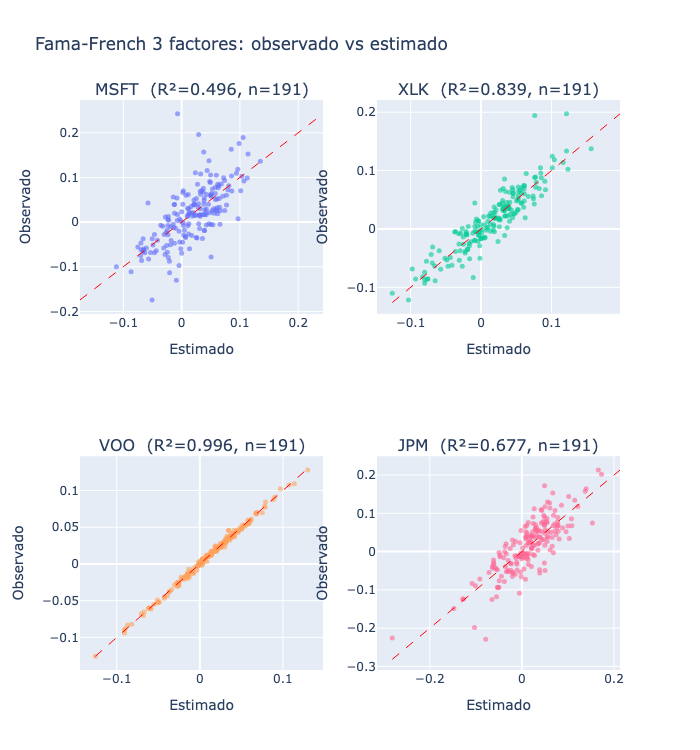

In [24]:
fig = make_subplots(rows=2, cols=2, subplot_titles=[
    f"{t}  (R²={resultados[t]['R2']:.3f}, n={resultados[t]['n']})" for t in tickers])
meses = datos.index.astype(str)

for i, t in enumerate(tickers):
    r = resultados[t]
    y_obs = r["y"].ravel()
    y_hat = r["y_hat"].ravel()
    fila, col = i // 2 + 1, i % 2 + 1
    fig.add_trace(go.Scatter(x=y_hat, y=y_obs, mode="markers", text=meses,
                             marker=dict(size=5, opacity=0.6),
                             hovertemplate="%{text}<br>estimado=%{x:.3f}<br>observado=%{y:.3f}<extra></extra>"),
                  row=fila, col=col)
    lims = [min(y_hat.min(), y_obs.min()), max(y_hat.max(), y_obs.max())]
    fig.add_trace(go.Scatter(x=lims, y=lims, mode="lines", hoverinfo="skip",
                             line=dict(color="red", dash="dash", width=1)),
                  row=fila, col=col)
    fig.update_xaxes(title_text="Estimado", row=fila, col=col)
    fig.update_yaxes(title_text="Observado", row=fila, col=col)

fig.update_layout(title="Fama-French 3 factores: observado vs estimado",
                  height=750, showlegend=False)
guardar_figura(fig, "observado_vs_estimado")

### Diagnóstico de residuos $\hat\varepsilon_{i,t} = R^e_{i,t} - \hat R^e_{i,t}$
- **Autocorrelación:** Durbin-Watson (≈ 2 indica que no hay autocorrelación).
- **Heterocedasticidad:** Breusch-Pagan (p < 0.05 indica varianza no constante).
- **Valores extremos:** residuos estandarizados con $|z| > 3$.

In [25]:
def durbin_watson(resid):
    """DW = sum (e_t - e_{t-1})^2 / sum e_t^2."""
    e = resid.ravel()
    return float(((np.diff(e)) ** 2).sum() / (e ** 2).sum())


def breusch_pagan(resid, X):
    """
    BP auxiliar: regresa residuos^2 sobre X (sin constantes extra),
    devuelve el estadístico n*R2 y su p-value chi2 con k-1 gl.
    Implementamos CDF chi2 con la beta incompleta.
    """
    e2 = (resid.ravel() ** 2).reshape(-1, 1)
    aux = ols_qr(X, e2)                # usamos el mismo OLS
    lm = aux["n"] * aux["R2"]
    gl = X.shape[1] - 1
    # CDF chi2(k) = I_{x/2}(k/2, 1/2) ... implementacion via gamma incompleta
    # Usamos la relacion chi2(k) = Gamma(k/2, 2); aproximacion via serie:
    p = _chi2_sf(lm, gl)
    return lm, gl, p


def _gammainc_upper(s, x):
    """Gamma incompleta superior regularizada Q(s,x) (Lentz)."""
    if x < s + 1.0:
        # serie para P(s,x)
        term = 1.0 / s
        suma = term
        n = 1
        while abs(term) > 1e-14 * abs(suma) and n < 500:
            term *= x / (s + n)
            suma += term
            n += 1
        P = suma * math.exp(-x + s * math.log(x) - math.lgamma(s))
        return 1.0 - P
    else:
        # fraccion continua para Q(s,x)
        b = x + 1.0 - s
        c = 1.0 / 1e-30
        d = 1.0 / b
        h = d
        for i in range(1, 500):
            an = -i * (i - s)
            b += 2.0
            d = an * d + b
            if abs(d) < 1e-30:
                d = 1e-30
            c = b + an / c
            if abs(c) < 1e-30:
                c = 1e-30
            d = 1.0 / d
            delta = d * c
            h *= delta
            if abs(delta - 1.0) < 1e-14:
                break
        return h * math.exp(-x + s * math.log(x) - math.lgamma(s))


def _chi2_sf(x, gl):
    """P(chi2_gl > x)"""
    return _gammainc_upper(gl / 2.0, x / 2.0)


filas_diag = []
for t in tickers:
    r = resultados[t]
    dw = durbin_watson(r["resid"])
    lm, gl, p_bp = breusch_pagan(r["resid"], X)
    e = r["resid"].ravel()
    z = (e - e.mean()) / e.std(ddof=1)
    n_out = int((np.abs(z) > 3).sum())
    filas_diag.append({"Activo": t, "DW": dw, "BP": lm, "p_BP": p_bp, "extremos": n_out})

diagnostico = pd.DataFrame(filas_diag).set_index("Activo")
print(f"Breusch-Pagan con gl = {gl}; extremos = residuos con |z| > 3")
print(diagnostico.round(4))

Breusch-Pagan con gl = 3; extremos = residuos con |z| > 3
            DW      BP    p_BP  extremos
Activo                                  
MSFT    2.1764  0.9972  0.8019         2
XLK     1.9108  2.9516  0.3992         3
VOO     1.8095  8.8531  0.0313         2
JPM     2.0232  4.2029  0.2404         2


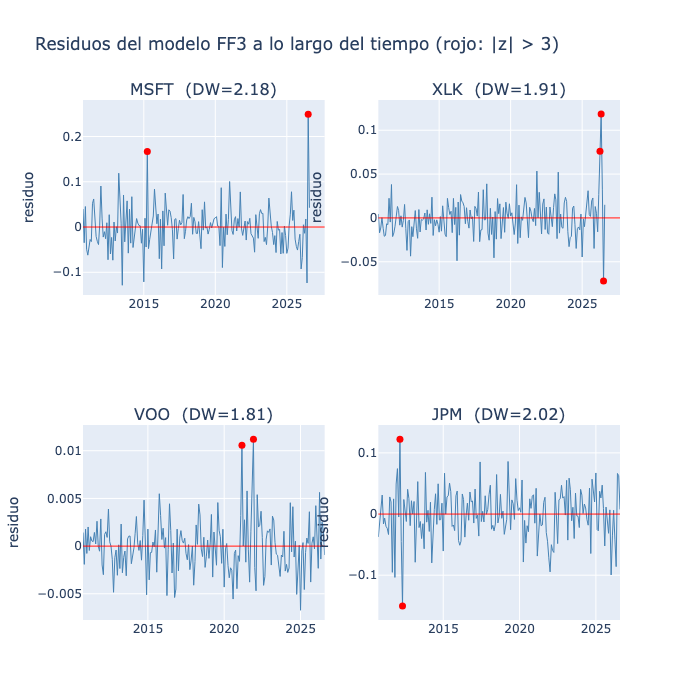

In [26]:
fig = make_subplots(rows=2, cols=2, subplot_titles=[
    f"{t}  (DW={durbin_watson(resultados[t]['resid']):.2f})" for t in tickers])
fechas = datos.index.to_timestamp()

for i, t in enumerate(tickers):
    e = resultados[t]["resid"].ravel()
    z = (e - e.mean()) / e.std(ddof=1)
    extremos = np.abs(z) > 3
    fila, col = i // 2 + 1, i % 2 + 1
    fig.add_trace(go.Scatter(x=fechas, y=e, mode="lines",
                             line=dict(color="steelblue", width=1)),
                  row=fila, col=col)
    # Valores extremos (|z| > 3) marcados en rojo
    fig.add_trace(go.Scatter(x=fechas[extremos], y=e[extremos], mode="markers",
                             marker=dict(color="red", size=7)),
                  row=fila, col=col)
    fig.add_hline(y=0, line=dict(color="red", width=1), row=fila, col=col)
    fig.update_yaxes(title_text="residuo", row=fila, col=col)

fig.update_layout(title="Residuos del modelo FF3 a lo largo del tiempo (rojo: |z| > 3)",
                  height=700, showlegend=False)
guardar_figura(fig, "residuos")

### Errores estándar robustos (White, HC0)
Los SE clásicos suponen varianza constante de los residuos. Como complemento (sin reemplazar la tabla principal) se calculan los SE de White:
$$\widehat{Var}_{HC0}(\hat\theta) = (X^TX)^{-1}X^T\,\mathrm{diag}(\hat\varepsilon^2)\,X\,(X^TX)^{-1}.$$
Con $X = QR$ se tiene $(X^TX)^{-1}X^T = R^{-1}Q^T$, que se obtiene resolviendo $RA = Q^T$ por sustitución hacia atrás (sin calcular inversas). Entonces $\widehat{Var}_{HC0} = A\,\mathrm{diag}(\hat\varepsilon^2)\,A^T$.

In [27]:
def se_robustos_hc0(X, resid):
    """SE de White (HC0) usando QR y sustitución hacia atrás."""
    Q, R = np.linalg.qr(np.asarray(X, dtype=float), mode="reduced")
    A = sustitucion_atras(R, Q.T)          # R A = Q^T
    e2 = np.asarray(resid, dtype=float).ravel() ** 2
    var = (A * e2) @ A.T                   # A diag(e^2) A^T
    return np.sqrt(np.diag(var)).reshape(-1, 1)


filas_hc0 = []
for t in tickers:
    r = resultados[t]
    se_hc0 = se_robustos_hc0(X, r["resid"])
    gl = r["n"] - r["k"]
    for j, nombre in enumerate(nombres_coef):
        t_hc0 = float(r["theta"][j, 0] / se_hc0[j, 0])
        filas_hc0.append({
            "Activo": t, "Coeficiente": nombre,
            "SE_clasico": float(r["se"][j, 0]), "p_clasico": float(r["p"][j, 0]),
            "SE_HC0": float(se_hc0[j, 0]), "p_HC0": t_pvalue_dos_colas(t_hc0, gl),
        })

comparacion_se = pd.DataFrame(filas_hc0).set_index(["Activo", "Coeficiente"])
print(comparacion_se.round(4))

hetero = diagnostico.index[diagnostico["p_BP"] < 0.05].tolist()
print("\nActivos con heterocedasticidad (Breusch-Pagan, p < 0.05):", hetero or "ninguno")
cambia = comparacion_se[(comparacion_se["p_clasico"] < 0.05) != (comparacion_se["p_HC0"] < 0.05)]
print("Coeficientes cuya significancia al 5% cambia con HC0:")
print(cambia.round(4) if len(cambia) else "ninguno")

                    SE_clasico  p_clasico  SE_HC0   p_HC0
Activo Coeficiente                                       
MSFT   alpha            0.0035     0.1175  0.0034  0.1052
       beta_M           0.0851     0.0000  0.0679  0.0000
       s_SMB            0.1405     0.0000  0.1390  0.0000
       h_HML            0.1097     0.0041  0.0857  0.0003
XLK    alpha            0.0016     0.1194  0.0015  0.0879
       beta_M           0.0393     0.0000  0.0421  0.0000
       s_SMB            0.0649     0.0000  0.0603  0.0000
       h_HML            0.0507     0.0000  0.0476  0.0000
VOO    alpha            0.0002     0.8889  0.0002  0.8808
       beta_M           0.0050     0.0000  0.0049  0.0000
       s_SMB            0.0082     0.0000  0.0091  0.0000
       h_HML            0.0064     0.0000  0.0076  0.0000
JPM    alpha            0.0031     0.4109  0.0031  0.4168
       beta_M           0.0742     0.0000  0.0819  0.0000
       s_SMB            0.1225     0.5380  0.1165  0.5173
       h_HML  

### Exportar tablas para el reporte
Todo se guarda en la carpeta `resultados/`:
- `tabla_coef_ff3.tex`: coeficientes y $R^2$ (entregable §2.1, punto 2).
- `tabla_inferencia_ff3.tex`: coeficientes, SE, $t$, p-values y $R^2$ (§1.5).
- `tabla_correlaciones.tex`: matriz de correlaciones de los rendimientos excedentes (§2.1, punto 1).
- `tabla_diagnostico_residuos.tex`: Durbin-Watson, Breusch-Pagan y valores extremos (§1.5).
- `tabla_se_robustos.tex`: SE clásicos vs. HC0.
- `tabla_coeficientes_ff3.csv`: tabla completa sin redondear.
- `correlaciones.png`, `observado_vs_estimado.png`, `residuos.png`: figuras.

In [28]:
ENCABEZADOS = {
    "R2": r"$R^2$", "alpha": r"$\hat\alpha$", "beta_M": r"$\hat\beta_M$",
    "s_SMB": r"$\hat s$", "h_HML": r"$\hat h$",
}


def escapar_latex(texto):
    """Escapa caracteres especiales; el texto que ya es LaTeX ($...$) se deja igual."""
    texto = str(texto)
    if texto.startswith("$"):
        return texto
    for c in ["&", "%", "_", "#"]:
        texto = texto.replace(c, "\\" + c)
    return texto


def formato_celda(v, decimales):
    if isinstance(v, (int, np.integer)):
        return str(v)
    if isinstance(v, (float, np.floating)):
        return f"{v:.{decimales}f}"
    return escapar_latex(v)


def p_a_texto(p):
    return "$<0.001$" if p < 0.001 else f"{p:.3f}"


def tabla_a_latex(df, decimales=3, renombrar=None):
    """Tabla LaTeX; `renombrar` mapea nombres de columna a encabezados LaTeX."""
    renombrar = renombrar or {}
    cols = list(df.columns)
    encabezados = [renombrar.get(c, escapar_latex(c)) for c in cols]
    out = [r"\begin{tabular}{l" + "r" * len(cols) + "}", r"\hline",
           escapar_latex(df.index.name or "") + " & " + " & ".join(encabezados) + r" \\",
           r"\hline"]
    for i, idx in enumerate(df.index):
        vals = [formato_celda(df[c].iloc[i], decimales) for c in cols]
        out.append(escapar_latex(idx) + " & " + " & ".join(vals) + r" \\")
    out += [r"\hline", r"\end{tabular}"]
    return "\n".join(out)


def guardar_tex(nombre, texto):
    ruta = os.path.join(CARPETA_RESULTADOS, nombre)
    with open(ruta, "w", encoding="utf-8") as f:
        f.write(texto + "\n")
    print(f"--- {ruta} ---")
    print(texto, "\n")


tabla.to_csv(os.path.join(CARPETA_RESULTADOS, "tabla_coeficientes_ff3.csv"))

# 1) Coeficientes y R²
guardar_tex("tabla_coef_ff3.tex",
            tabla_a_latex(tabla[["R2", "alpha", "beta_M", "s_SMB", "h_HML"]], 3, ENCABEZADOS))

# 2) Inferencia: una fila por activo y coeficiente
filas_inf = []
for t in tickers:
    r = resultados[t]
    for j, nombre in enumerate(nombres_coef):
        filas_inf.append({
            "Activo": t if j == 0 else "",
            "Coeficiente": ENCABEZADOS[nombre],
            "Estimación": f"{r['theta'][j, 0]:.4f}",
            "SE": f"{r['se'][j, 0]:.4f}",
            "$t$": f"{r['t'][j, 0]:.2f}",
            "$p$": p_a_texto(r["p"][j, 0]),
            "$R^2$": f"{r['R2']:.3f}" if j == 0 else "",
        })
guardar_tex("tabla_inferencia_ff3.tex",
            tabla_a_latex(pd.DataFrame(filas_inf).set_index("Activo")))

# 3) Matriz de correlaciones de los rendimientos excedentes
guardar_tex("tabla_correlaciones.tex", tabla_a_latex(matriz_corr, 3))

# 4) Diagnóstico de residuos
guardar_tex("tabla_diagnostico_residuos.tex",
            tabla_a_latex(diagnostico.assign(p_BP=diagnostico["p_BP"].map(p_a_texto)), 3,
                          {"BP": "BP (LM)", "p_BP": "$p$ BP", "extremos": r"Extremos ($|z|>3$)"}))

# 5) SE clásicos vs. HC0
se_tex = comparacion_se.reset_index()
se_tex["Activo"] = se_tex["Activo"].where(se_tex["Coeficiente"] == nombres_coef[0], "")
se_tex["Coeficiente"] = se_tex["Coeficiente"].map(ENCABEZADOS)
se_tex["p_clasico"] = se_tex["p_clasico"].map(p_a_texto)
se_tex["p_HC0"] = se_tex["p_HC0"].map(p_a_texto)
guardar_tex("tabla_se_robustos.tex",
            tabla_a_latex(se_tex.set_index("Activo"), 4,
                          {"SE_clasico": "SE clásico", "p_clasico": "$p$ clásico",
                           "SE_HC0": "SE HC0", "p_HC0": "$p$ HC0"}))

--- resultados/tabla_coef_ff3.tex ---
\begin{tabular}{lrrrrr}
\hline
Activo & $R^2$ & $\hat\alpha$ & $\hat\beta_M$ & $\hat s$ & $\hat h$ \\
\hline
MSFT & 0.496 & 0.006 & 1.067 & -0.767 & -0.319 \\
XLK & 0.839 & 0.003 & 1.164 & -0.337 & -0.328 \\
VOO & 0.996 & 0.000 & 0.986 & -0.135 & 0.039 \\
JPM & 0.677 & 0.003 & 1.181 & 0.076 & 0.869 \\
\hline
\end{tabular} 

--- resultados/tabla_inferencia_ff3.tex ---
\begin{tabular}{lrrrrrr}
\hline
Activo & Coeficiente & Estimación & SE & $t$ & $p$ & $R^2$ \\
\hline
MSFT & $\hat\alpha$ & 0.0055 & 0.0035 & 1.57 & 0.117 & 0.496 \\
 & $\hat\beta_M$ & 1.0671 & 0.0851 & 12.55 & $<0.001$ &  \\
 & $\hat s$ & -0.7673 & 0.1405 & -5.46 & $<0.001$ &  \\
 & $\hat h$ & -0.3191 & 0.1097 & -2.91 & 0.004 &  \\
XLK & $\hat\alpha$ & 0.0025 & 0.0016 & 1.56 & 0.119 & 0.839 \\
 & $\hat\beta_M$ & 1.1638 & 0.0393 & 29.63 & $<0.001$ &  \\
 & $\hat s$ & -0.3369 & 0.0649 & -5.19 & $<0.001$ &  \\
 & $\hat h$ & -0.3277 & 0.0507 & -6.47 & $<0.001$ &  \\
VOO & $\hat\alpha$ & 0.